In [0]:
# Install required packages
%pip install spacy
%pip install https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.7.1/en_core_web_sm-3.7.1-py3-none-any.whl
%pip install --upgrade matplotlib seaborn

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 106.0 MB/s eta 0:00:00
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 119.0 MB/s eta 0:00:00
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Not uninstalling matplotlib at /databricks/python3/lib/python3.12/site-packages, outside environment /local_disk0/.ephemeral_nfs/envs/pythonEnv-363ec4d2-87c2-4976-8ae9-993d31d9dda5
    Can't uninstall 'matplotlib'. No files were found to uninstall.
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
dbutils.library.restartPython()

In [0]:
import spacy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [0]:
import spacy

# Load the English language model
nlp = spacy.load("en_core_web_sm")

# Sample text for analysis
text = """
Apple Inc. CEO Tim Cook announced new AI features for iPhones at their headquarters 
in Cupertino, California yesterday. The company plans to invest $10 billion in AI 
research over the next 5 years, starting from January 2025.
"""

# Process the text
doc = nlp(text)

# Print entities with their labels
print("Named Entities Found:")
for ent in doc.ents:
    print(f"Text: {ent.text:<30} Label: {ent.label_:<10} Description: {spacy.explain(ent.label_)}")


Named Entities Found:
Text: Apple Inc.                     Label: ORG        Description: Companies, agencies, institutions, etc.
Text: Tim Cook                       Label: PERSON     Description: People, including fictional
Text: AI                             Label: ORG        Description: Companies, agencies, institutions, etc.
Text: iPhones                        Label: ORG        Description: Companies, agencies, institutions, etc.
Text: Cupertino                      Label: GPE        Description: Countries, cities, states
Text: California                     Label: GPE        Description: Countries, cities, states
Text: yesterday                      Label: DATE       Description: Absolute or relative dates or periods
Text: $10 billion                    Label: MONEY      Description: Monetary values, including unit
Text: AI                             Label: ORG        Description: Companies, agencies, institutions, etc.
Text: the next 5 years               Label: DATE       D

In [0]:
def analyze_entities(text):
    doc = nlp(text)
    
    # Create a DataFrame of entities
    entities = [(ent.text, ent.label_, spacy.explain(ent.label_)) 
               for ent in doc.ents]
    
    df = pd.DataFrame(entities, columns=['Entity', 'Label', 'Description'])
    
    # Get entity counts
    label_counts = df['Label'].value_counts()
    
    return df, label_counts

# Analyze text
df_entities, entity_counts = analyze_entities(text)

print("\nEntity Analysis Summary:")
print(df_entities)
print("\nEntity Type Counts:")
print(entity_counts)



Entity Analysis Summary:
              Entity   Label                              Description
0         Apple Inc.     ORG  Companies, agencies, institutions, etc.
1           Tim Cook  PERSON              People, including fictional
2                 AI     ORG  Companies, agencies, institutions, etc.
3            iPhones     ORG  Companies, agencies, institutions, etc.
4          Cupertino     GPE                Countries, cities, states
5         California     GPE                Countries, cities, states
6          yesterday    DATE    Absolute or relative dates or periods
7        $10 billion   MONEY          Monetary values, including unit
8                 AI     ORG  Companies, agencies, institutions, etc.
9   the next 5 years    DATE    Absolute or relative dates or periods
10      January 2025    DATE    Absolute or relative dates or periods

Entity Type Counts:
Label
ORG       4
DATE      3
GPE       2
PERSON    1
MONEY     1
Name: count, dtype: int64


In [0]:
def analyze_entities(text):
    doc = nlp(text)
    
    # Create a DataFrame of entities
    entities = [(ent.text, ent.label_, spacy.explain(ent.label_)) 
               for ent in doc.ents]
    
    df = pd.DataFrame(entities, columns=['Entity', 'Label', 'Description'])
    
    # Get entity counts
    label_counts = df['Label'].value_counts()
    
    return df, label_counts

# Analyze text
df_entities, entity_counts = analyze_entities(text)

print("\nEntity Analysis Summary:")
print(df_entities)
print("\nEntity Type Counts:")
print(entity_counts)



Entity Analysis Summary:
              Entity   Label                              Description
0         Apple Inc.     ORG  Companies, agencies, institutions, etc.
1           Tim Cook  PERSON              People, including fictional
2                 AI     ORG  Companies, agencies, institutions, etc.
3            iPhones     ORG  Companies, agencies, institutions, etc.
4          Cupertino     GPE                Countries, cities, states
5         California     GPE                Countries, cities, states
6          yesterday    DATE    Absolute or relative dates or periods
7        $10 billion   MONEY          Monetary values, including unit
8                 AI     ORG  Companies, agencies, institutions, etc.
9   the next 5 years    DATE    Absolute or relative dates or periods
10      January 2025    DATE    Absolute or relative dates or periods

Entity Type Counts:
Label
ORG       4
DATE      3
GPE       2
PERSON    1
MONEY     1
Name: count, dtype: int64


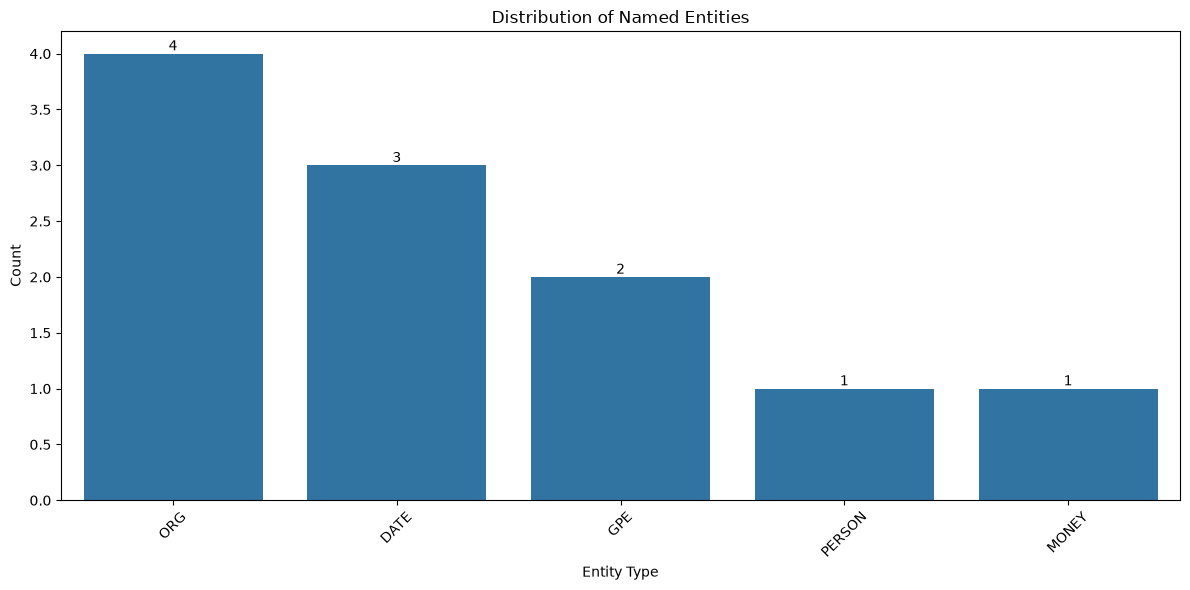

In [0]:
def plot_entity_distribution(entity_counts):
    plt.figure(figsize=(12, 6))
    sns.barplot(x=entity_counts.index, y=entity_counts.values)
    plt.title('Distribution of Named Entities')
    plt.xlabel('Entity Type')
    plt.ylabel('Count')
    
    # Add value labels on top of bars
    for I, v in enumerate(entity_counts.values):
        plt.text(I, v, str(v), ha='center', va='bottom')
    
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

plot_entity_distribution(entity_counts)


In [0]:
def analyze_entity_context(doc, window=2):
    context_info = []
    
    for ent in doc.ents:
        # Get token indices for the entity
        start = max(0, ent.start - window)
        end = min(len(doc), ent.end + window)
        
        # Get context words
        context = doc[start:end].text
        
        context_info.append({
            'Entity': ent.text,
            'Type': ent.label_,
            'Context': context
        })
    
    return pd.DataFrame(context_info)

# Analyze context
context_df = analyze_entity_context(nlp(text))
print("\nEntity Context Analysis:")
print(context_df)



Entity Context Analysis:
              Entity    Type                                   Context
0         Apple Inc.     ORG                      \nApple Inc. CEO Tim
1           Tim Cook  PERSON           Inc. CEO Tim Cook announced new
2                 AI     ORG             announced new AI features for
3            iPhones     ORG             features for iPhones at their
4          Cupertino     GPE                \nin Cupertino, California
5         California     GPE          Cupertino, California yesterday.
6          yesterday    DATE               , California yesterday. The
7        $10 billion   MONEY               to invest $10 billion in AI
8                 AI     ORG                  billion in AI \nresearch
9   the next 5 years    DATE  research over the next 5 years, starting
10      January 2025    DATE             starting from January 2025.\n


In [0]:
# Add custom patterns for entity recognition
ruler = nlp.add_pipe("entity_ruler", before="ner")
patterns = [
    {"label": "PRODUCT", "pattern": "iPhone"},
    {"label": "TECH", "pattern": "AI"}
]
ruler.add_patterns(patterns)

# Process text with custom patterns
doc_custom = nlp(text)
print("\nEntities with Custom Patterns:")
for ent in doc_custom.ents:
    print(f"{ent.text:<20} {ent.label_:<10}")



Entities with Custom Patterns:
Apple Inc.           ORG       
Tim Cook             PERSON    
AI                   TECH      
iPhones              ORG       
Cupertino            GPE       
California           GPE       
yesterday            DATE      
$10 billion          MONEY     
AI                   TECH      
the next 5 years     DATE      
January 2025         DATE      


# Custom Entity Recognition with spaCy's EntityRuler

Using spaCy's EntityRuler allows you to add custom patterns for Named Entity Recognition (NER). This approach combines rule-based matching with statistical models, making entity analysis significantly more accurate and flexible for domain-specific terminology (e.g., detecting product names or tech acronyms like "iPhone" and "AI").